In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1
df = pd.read_csv('medical_examination.csv')
Hieght = (df['height']*0.01)
Weight = df['weight']
BMI = Weight/(Hieght**2)
    


# 2
df['overweight'] = (BMI > 25).astype(int)
    
    

# 3
df['cholesterol'] = df['cholesterol'].apply(lambda x:0 if x == 1 else 1)
df['gluc'] = df['gluc'].apply(lambda x:0 if x == 1 else 1)






# 4
def draw_cat_plot():
    # 5
    df_melt = pd.melt(df,id_vars =['cardio'],value_vars = ['active', 'alco', 'cholesterol', 'gluc', 'overweight', 'smoke'],var_name = 'variable',value_name = 'value')


    # 6
    df_cat = df_melt
    

    # 7

    catplot = sns.catplot(x = "variable",hue = "value",col = 'cardio',kind ='count',data = df_cat)
    catplot.set_axis_labels("variable", "total")


    # 8
    fig = catplot.fig


    # 9
    fig.savefig('catplot.png')
    return fig


# 10
def draw_heat_map():
    # 11
    df_heat = df[(df['height']>= df['height'].quantile(0.025))& (df['height']<= df['height'].quantile(0.975)) & (df['weight']>=df['weight'].quantile(0.025))&(df['weight']<= df['weight'].quantile(0.975))& (df['ap_lo'] <= df['ap_hi'])]
    


    # 12
    corr = df_heat.corr()

    # 13
    mask = np.triu(np.ones_like(corr,dtype = bool ))



    # 14
    fig, ax = plt.subplots(figsize = (10,8))
    # 15
    sns.heatmap(corr,mask = mask,fmt = '.1f', annot = True, cmap = 'coolwarm', linewidths = 0.5, ax = ax)
  

    # 16
    fig.savefig('heatmap.png')
    return fig


In [5]:
df = pd.read_csv('medical_examination.csv')
Hieght = (df['height']*0.01)
Weight = df['weight']
BMI = Weight/(Hieght**2)
    


# 2
df['overweight'] = (BMI > 25).astype(int)
print(df[['height', 'weight', 'overweight']].head())



df['cholesterol'] = df['cholesterol'].apply(lambda x:0 if x == 1 else 1)
df['gluc'] = df['gluc'].apply(lambda x:0 if x == 1 else 1)






   height  weight  overweight
0     168    62.0           0
1     156    85.0           1
2     165    64.0           0
3     169    82.0           1
4     156    56.0           0


In [6]:
print(df[['cholesterol', 'gluc']].head())

   cholesterol  gluc
0            0     0
1            1     0
2            1     0
3            0     0
4            0     0


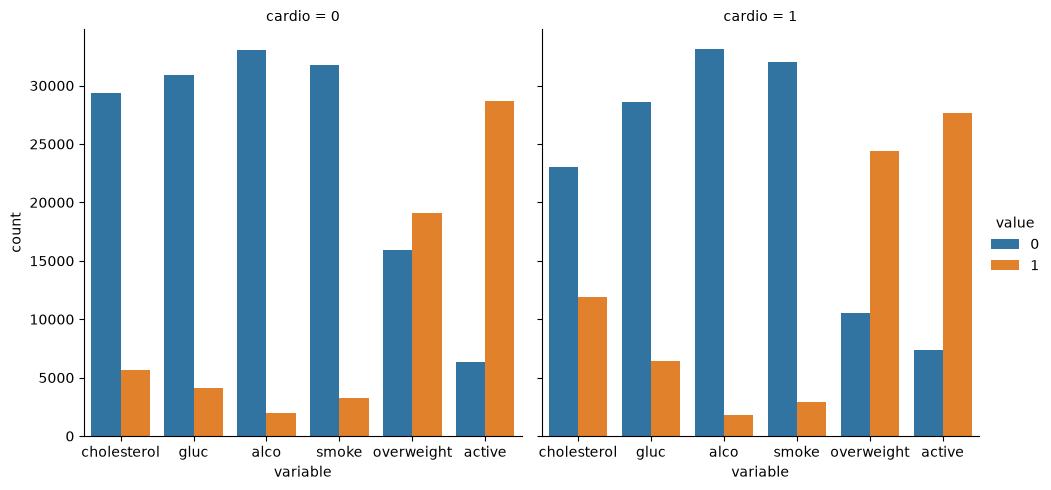

In [7]:

#ALTERNATIVE 
df = pd.read_csv('medical_examination.csv')
df['height_m'] = df['height'] * 0.01  # Convert height to meters
df['BMI'] = df['weight'] / (df['height_m'] ** 2)  # BMI calculation

# 3. Create 'overweight' column (1 if BMI > 25, else 0)
df['overweight'] = (df['BMI'] > 25).astype(int)

    


# 2

df['cholesterol'] = df['cholesterol'].apply(lambda x:0 if x == 1 else 1)
df['gluc'] = df['gluc'].apply(lambda x:0 if x == 1 else 1)


# 2. Select columns to melt (cholesterol, gluc, alco, smoke)
df_melt = pd.melt(df, id_vars = ['cardio'], value_vars = ['cholesterol', 'gluc', 'alco', 'smoke','overweight','active'], 
                  var_name = 'variable', value_name = 'value') 

# 3. Create a categorical plot
sns.catplot(x="variable", hue="value", col="cardio", kind="count", data=df_melt)

# 4. Show the plot
plt.show()


In [8]:
df = pd.read_csv('medical_examination.csv')
Hieght = (df['height']*0.01)
Weight = df['weight']
BMI = Weight/(Hieght**2)
    


# 2
df['overweight'] = (BMI > 25).astype(int)
    
    

# 3
df['cholesterol'] = df['cholesterol'].apply(lambda x:0 if x == 1 else 1)
df['gluc'] = df['gluc'].apply(lambda x:0 if x == 1 else 1)





# 4
def draw_cat_plot():
    # 5
    df_melt = pd.melt(df,id_vars =['cardio'],value_vars = ['cholesterol','gluc','smoke','overweight','alco','active'],var_name = 'variable',value_name = 'value')


    # 6
    df_cat = df_melt
    

    # 7



    # 8
    fig = sns.catplot(x = "variable",hue = "value",col = 'cardio',kind ='count',data = df_cat)


    # 9
    fig.savefig('catplot.png')
    return fig



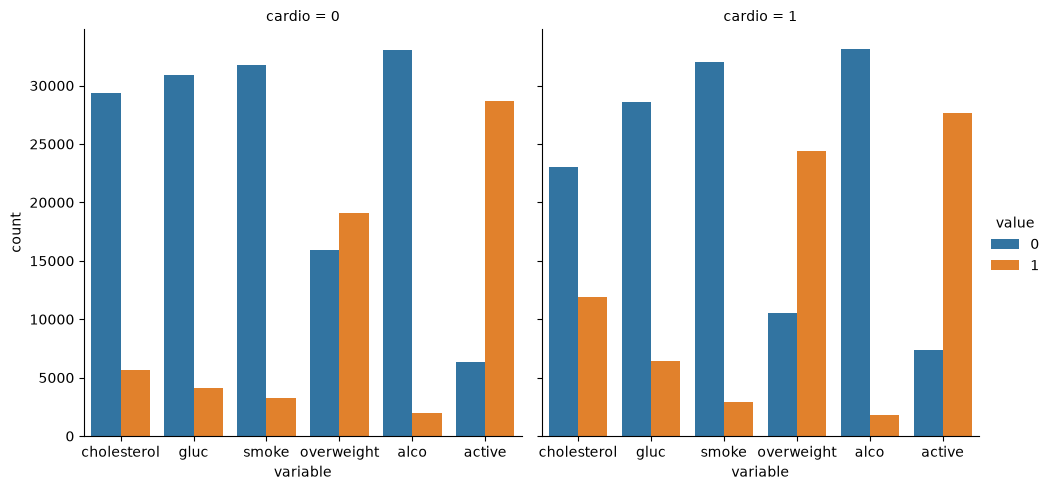

In [9]:
draw_cat_plot()

In [10]:
df['overweight']

0        0
1        1
2        0
3        1
4        0
        ..
69995    1
69996    1
69997    1
69998    1
69999    0
Name: overweight, Length: 70000, dtype: int64

In [11]:
df

,id,age,sex,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,overweight
0,0,18393,2,168,62.0,110,80,0,0,0,0,1,0,0
1,1,20228,1,156,85.0,140,90,1,0,0,0,1,1,1
2,2,18857,1,165,64.0,130,70,1,0,0,0,0,1,0
3,3,17623,2,169,82.0,150,100,0,0,0,0,1,1,1
4,4,17474,1,156,56.0,100,60,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,99993,19240,2,168,76.0,120,80,0,0,1,0,1,0,1
69996,99995,22601,1,158,126.0,140,90,1,1,0,0,1,1,1
69997,99996,19066,2,183,105.0,180,90,1,0,0,1,0,1,1
69998,99998,22431,1,163,72.0,135,80,0,1,0,0,0,1,1


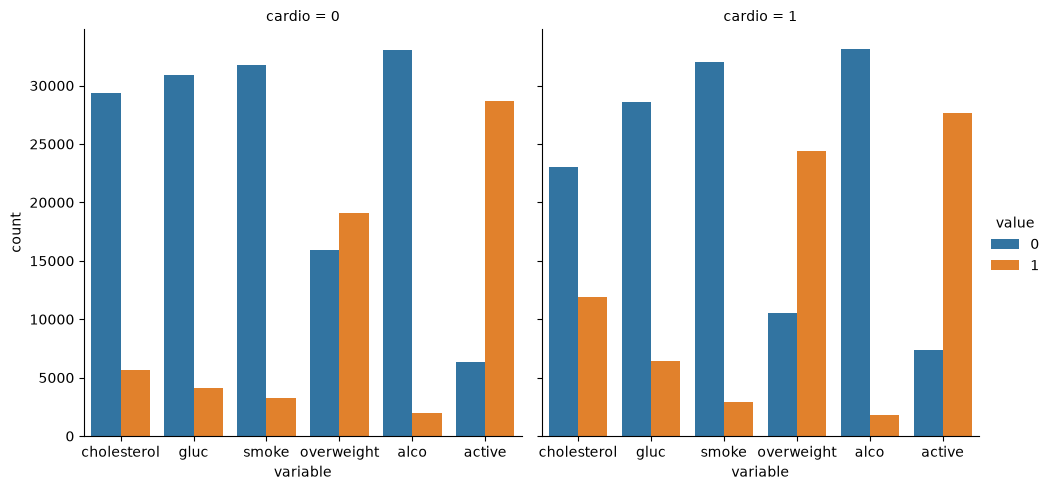

In [12]:
draw_cat_plot()

In [13]:
    df_heat = df[(df['height']>= df['height'].quantile(0.025))& (df['height']<= df['height'].quantile(0.975)) & (df['weight']>=df['weight'].quantile(0.025))&(df['weight']<= df['weight'].quantile(0.975))]
    


In [14]:
df_heat

,id,age,sex,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,overweight
0,0,18393,2,168,62.0,110,80,0,0,0,0,1,0,0
1,1,20228,1,156,85.0,140,90,1,0,0,0,1,1,1
2,2,18857,1,165,64.0,130,70,1,0,0,0,0,1,0
3,3,17623,2,169,82.0,150,100,0,0,0,0,1,1,1
4,4,17474,1,156,56.0,100,60,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69993,99991,19699,1,172,70.0,130,90,0,0,0,0,1,1,0
69994,99992,21074,1,165,80.0,150,80,0,0,0,0,1,1,1
69995,99993,19240,2,168,76.0,120,80,0,0,1,0,1,0,1
69998,99998,22431,1,163,72.0,135,80,0,1,0,0,0,1,1


In [15]:
correlation = df_heat.corr()

<Axes: >

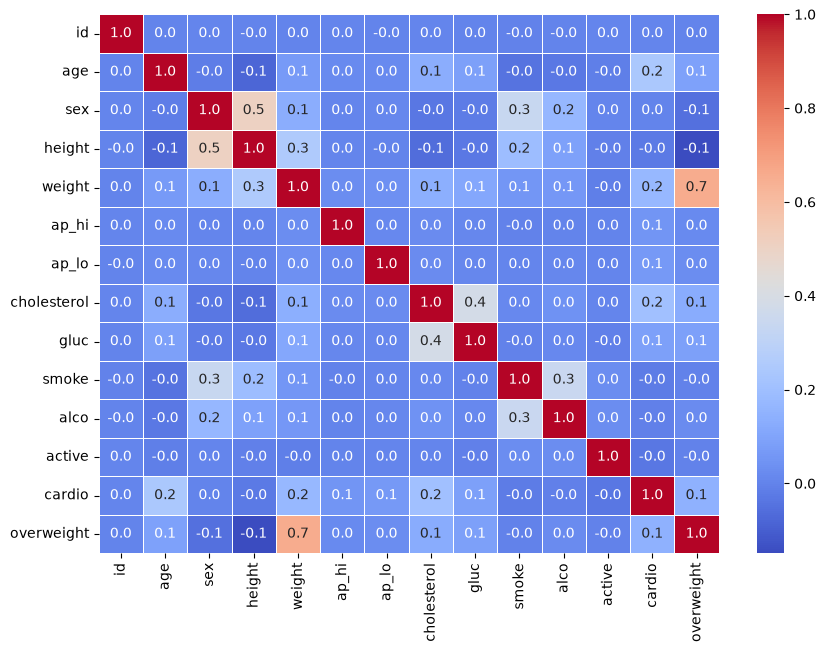

In [18]:
plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True,fmt ='.1f', cmap='coolwarm', linewidths=0.7)


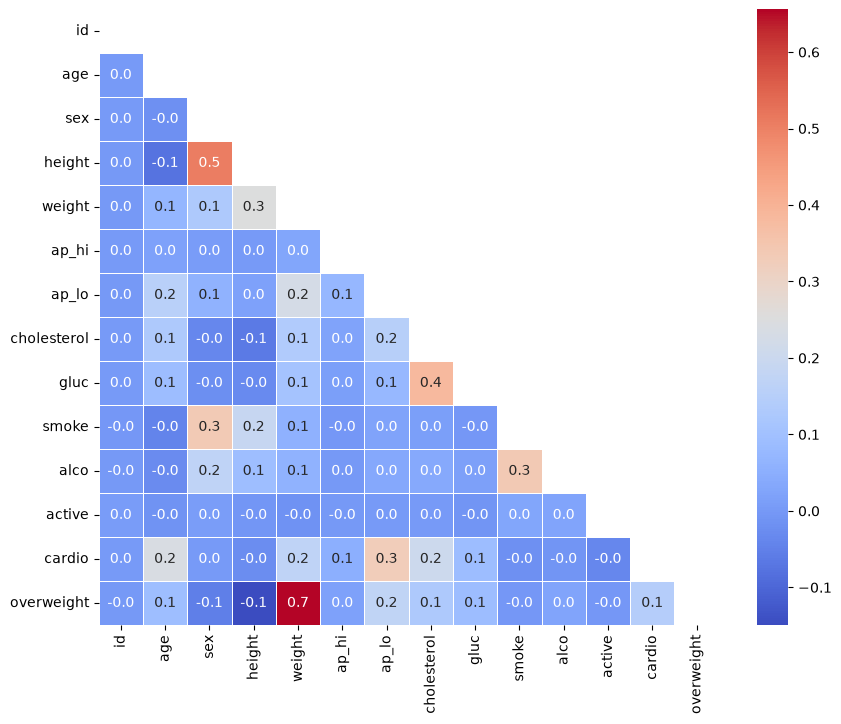

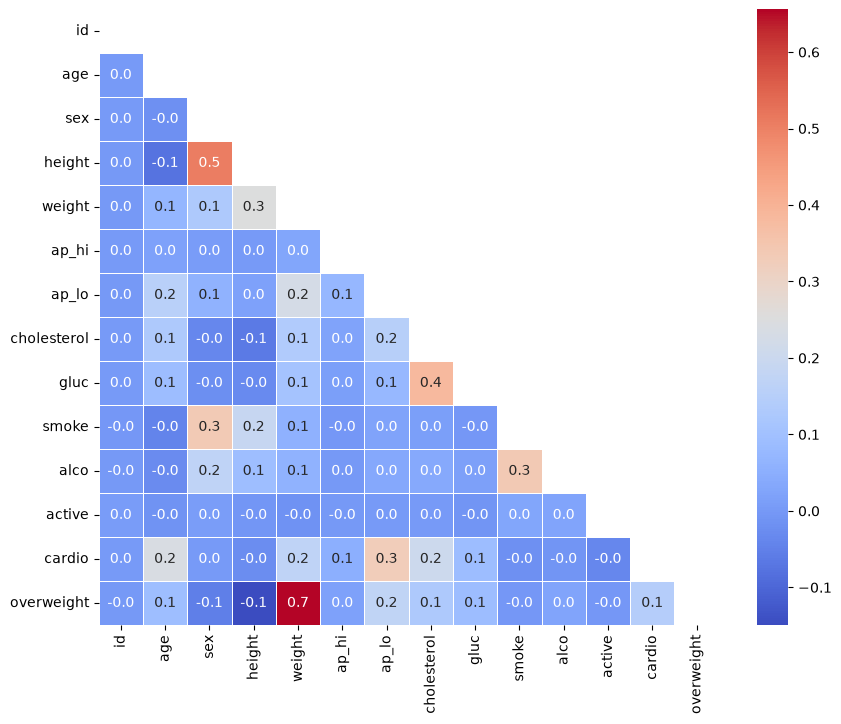

In [19]:
draw_heat_map()